# End-to-end TCR pipeline tutorial: SCEPTR + FAISS k-means + Fisher filter, in Python

This notebook walks through the final configuration of this repository on a **tiny CPU subset** of the data, using the Python API (`src/*`) only:

1. build a small, reproducible subset of `data/raw`;
2. embed the CDR3 sequences with **SCEPTR** (pretrained, 64-d);
3. tune the hyperparameters: the **one-vs-rest Fisher sequence filter** (strictness grid), the **FAISS k-means** clustering grid (number of clusters K and per-cluster radius quantile), then XGBoost with Optuna;
4. run the final fit **with the Fisher filter switched on** (the same filter that was used during tuning) and predict;
5. evaluate it with 3-class metrics;
6. explain the final model with **SHAP**.

**The task.** Predict `disease_group` (`autoimmunity` / `cancer` / `infection`) of a TCR beta repertoire from its CDR3 sequences. The model is: SCEPTR embedding → Fisher filter on the training sequences → FAISS k-means clusters with a per-cluster radius → per-sample cluster-occupancy features → class-aware prevalence filter → XGBoost. Everything that uses labels (the Fisher filter, the clustering, the prevalence filter) is **refit inside every CV fold** on that fold's training samples only, so nothing leaks into the validation samples.

**Environment.** The kernel must be the Conda environment **`sceptr_env`** (SCEPTR, FAISS, PyTorch, XGBoost; `env/sceptr_env_mac.yml` or `env/sceptr_env_linux.yml`). The first code cell checks it. Settings that change on a GPU server are `XGB_DEVICE` and `KMEANS_DEVICE` in that cell (the embedding model has its own `--device`-style setting, `EMBED_DEVICE`). The subset is small so the notebook finishes in a few minutes on a laptop. Nothing in `data/raw` is ever modified.

> **Read the numbers with care.** The subset has 24 training repertoires with 3,000 sequences each, so the metrics below only show that the machinery works. They are not an estimate of how the full-data model performs, and the hold-out set has only 9 samples.

## Step 1. Environment setup

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def find_root(start=Path.cwd()):
    for d in [start, *start.parents]:
        if (d / "run_pipeline.py").exists():
            return d
    raise RuntimeError("run this notebook from inside the project (run_pipeline.py not found)")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

EMBED_DEVICE = "cpu"      # SCEPTR inference: "cuda" on the GPU server
XGB_DEVICE = "cpu"        # XGBoost: "cuda" on the GPU server (CLI name: --xgboost_device)
KMEANS_DEVICE = "cpu"     # FAISS: keep "cpu" unless your FAISS build has kernels for your GPU (CLI name: --kmeans_device)
SEED = 42
N_JOBS = 4

TUT = ROOT / "data" / "tutorial"       # the subset: raw/ and embeddings/ live here
RES = ROOT / "results" / "tutorial"    # everything this notebook saves
TUT.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

import faiss, torch, xgboost, shap, sceptr, sklearn
print("project root :", ROOT)
print("python       :", sys.executable)
print(f"faiss {faiss.__version__} | torch {torch.__version__} | xgboost {xgboost.__version__} | shap {shap.__version__} | "
      f"sceptr {getattr(sceptr, '__version__', '?')} | scikit-learn {sklearn.__version__}")
if "sceptr_env" not in sys.executable:
    print("WARNING: this kernel is not the sceptr_env conda environment")

project root : /Users/artux/Documents/tcr_hackatomics
python       : /Users/artux/miniforge3/envs/sceptr_env/bin/python
faiss 1.14.3 | torch 2.13.0 | xgboost 3.2.0 | shap 0.48.0 | sceptr ? | scikit-learn 1.7.2


### A tiny, reproducible subset of the data

The full repertoires have 30k-200k clonotypes each, which is far too much for a CPU tutorial (SCEPTR embeds roughly 2,000-3,000 TCRs per second on a laptop). We therefore cut a subset **from `data/raw`** into `data/tutorial/raw/` with the same file format:

* `train`: 8 repertoires per class (24), spread over as many diseases as possible;
* `holdout`: 3 further labelled repertoires per class (9) that are **never used for training or tuning**, so we can score the final model on truly unseen, labelled samples (the real `test_bulk`/`test_sc` have no labels locally);
* `test_bulk`, `test_sc`: 6 unlabelled repertoires each;
* every repertoire is reduced to 3,000 randomly chosen rows.

`data/raw` stays untouched. The cell is skipped if the subset already exists.

In [2]:
from src import preprocessing as prep
from src import embeddings as emb

RAW = ROOT / "data" / "raw"
N_TRAIN_PER_CLASS, N_HOLDOUT_PER_CLASS, N_TEST, ROWS = 8, 3, 6, 3000

def pick_diseases_round_robin(meta, group, n, rng):
    """n samples of one class, taking one per disease in turn (as many diseases as possible)."""
    sub = meta[meta["disease_group"] == group]
    pools = {d: list(rng.permutation(g["sample_id"].to_numpy())) for d, g in sub.groupby("disease")}
    order, picked = list(rng.permutation(list(pools))), []
    while len(picked) < n and any(pools.values()):
        for d in order:
            if pools[d] and len(picked) < n:
                picked.append(pools[d].pop())
    return picked

def write_subset(name, ids, meta_src):
    out = TUT / "raw" / name
    out.mkdir(parents=True, exist_ok=True)
    meta_src[meta_src["sample_id"].isin(ids)].to_csv(out / "metadata.tsv", sep="\t", index=False)
    for sid in ids:
        src = "train" if name in ("train", "holdout") else name
        df = pd.read_csv(RAW / src / f"{sid}.tsv", sep="\t", dtype=str, keep_default_na=False)
        df.sample(n=min(ROWS, len(df)), random_state=SEED).to_csv(out / f"{sid}.tsv", sep="\t", index=False)

if (TUT / "raw" / "train" / "metadata.tsv").exists():
    print("subset already exists:", TUT / "raw")
else:
    rng = np.random.default_rng(SEED)
    train_meta = prep.load_metadata(RAW / "train")
    train_ids, holdout_ids = [], []
    for g in emb.CLASS_NAMES:
        ids = pick_diseases_round_robin(train_meta, g, N_TRAIN_PER_CLASS + N_HOLDOUT_PER_CLASS, rng)
        train_ids += ids[:N_TRAIN_PER_CLASS]
        holdout_ids += ids[N_TRAIN_PER_CLASS:]
    write_subset("train", train_ids, train_meta)
    write_subset("holdout", holdout_ids, train_meta)
    for ds in ("test_bulk", "test_sc"):
        m = prep.load_metadata(RAW / ds)
        write_subset(ds, sorted(rng.choice(m["sample_id"], N_TEST, replace=False)), m)

rows = []
for ds in ("train", "holdout", "test_bulk", "test_sc"):
    m = prep.load_metadata(TUT / "raw" / ds)
    rows.append({"dataset": ds, "samples": len(m),
                 "classes": m["disease_group"].value_counts().to_dict() if "disease_group" in m else "unlabelled",
                 "diseases": m["disease"].nunique() if "disease" in m else "-"})
display(pd.DataFrame(rows))
display(prep.load_metadata(TUT / "raw" / "train")["disease"].value_counts().rename("train samples per disease").to_frame().T)

subset already exists: /Users/artux/Documents/tcr_hackatomics/data/tutorial/raw


,dataset,samples,classes,diseases
0,train,24,"{'infection': 8, 'autoimmunity': 8, 'cancer': 8}",18
1,holdout,9,"{'cancer': 3, 'autoimmunity': 3, 'infection': 3}",9
2,test_bulk,6,unlabelled,-
3,test_sc,6,unlabelled,-


disease,CMV,Rheumatoid_arthritis,COVID-19,Multiple_sclerosis,Influenza,Primary_biliary_cholangitis,Breast_cancer,HIV,Tuberculosis,NSCLC,Ovarian_cancer,Multiple_myeloma,T1D,Classical_Hodgkin_lymphoma,Ulcerative_colitis,ESCC,Urothelial_cancer,HNSCC
train samples per disease,2,2,2,2,2,2,1,1,1,1,1,1,1,1,1,1,1,1


## Step 2. SCEPTR embeddings

SCEPTR is pretrained, so there is no training step: each **unique** `cdr3_aa+V_J` clonotype of a dataset is embedded once and the vectors are written per sample, in the format every later step reads. The generator applies the **same shared preprocessing** as the rest of the pipeline (`src/preprocessing.py`: canonical CDR3s only, junk and ambiguous V/J calls dropped, rows with no V or J call dropped, the 14 single-member V genes canonicalised, duplicates collapsed with their `clone_count` summed). SCEPTR specifics:

* it embeds the **beta chain together with its V gene** (it derives CDR1/CDR2 from the V gene); the J gene is not used by the model, it only stays part of the key;
* V genes must be functional IMGT names. About 1.3 % of the real training rows carry names it rejects (for example `TRBV1`, `TRBV12-1`, `TRBV21-1`); with `invalid_v_policy="drop"` (default) those rows are removed and logged;
* the vectors have unit length, so the clustering below uses cosine distance for them.

We call the generator's `main` function with an argument list (it is the same code the production scripts run); `device=EMBED_DEVICE`. Each dataset writes `<sample_id>_embed.csv` files, `per_patient_tcr_embed.h5`, `metadata.tsv`, `preprocessing_log.tsv` and `embedding_config.json`. Datasets that already have an `embedding_config.json` are skipped.

In [3]:
import contextlib, io
import generate_sceptr_embeddings as sceptr_gen
from src import embeddings as emb

for ds in ("train", "holdout", "test_bulk", "test_sc"):
    out_dir = TUT / "embeddings" / "sceptr" / ds
    if (out_dir / "embedding_config.json").exists():
        print(f"{ds}: already embedded, skipped")
        continue
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        sceptr_gen.main(["--input_path", str(TUT / "raw" / ds), "--output_path", str(out_dir),
                         "--device", EMBED_DEVICE, "--batch_size", "512", "--n_jobs", str(N_JOBS),
                         "--random_seed", str(SEED)])
    print(f"{ds}:", [l[:170] for l in buf.getvalue().splitlines() if l.startswith(("Dropped", "Embedding", "Done"))])

train: already embedded, skipped
holdout: already embedded, skipped
test_bulk: already embedded, skipped
test_sc: already embedded, skipped


In [4]:
# What the generator wrote
rows = []
for ds in ("train", "holdout", "test_bulk", "test_sc"):
    d = emb.embedding_dir(TUT, "sceptr", ds)
    cfg = emb.load_embedding_config(d)
    rows.append({"dataset": ds, "samples": cfg["n_samples"], "embedding_dim": cfg["embedding_dim"],
                 "unique clonotypes (sum over samples)": cfg["n_keys"],
                 "rows dropped (V gene rejected)": cfg.get("n_rows_dropped_invalid_v"), "seconds": cfg["elapsed_seconds"]})
display(pd.DataFrame(rows))

d = emb.embedding_dir(TUT, "sceptr", "train")
sid = emb.load_dataset_meta(d)["sample_id"][0]
print(f"\nfirst lines of {sid}_embed.csv: key -> 64 dims -> vj_call")
display(pd.read_csv(Path(d) / f"{sid}_embed.csv", index_col=0).iloc[:4, [0, 1, 2, 62, 63, 64]])

log = pd.read_csv(Path(d) / "preprocessing_log.tsv", sep="\t")
print("rows removed per preprocessing step, summed over the training samples:")
display(log.drop(columns="sample_id").sum().to_frame("rows").T)

,dataset,samples,embedding_dim,unique clonotypes (sum over samples),rows dropped (V gene rejected),seconds
0,train,24,64,59802,1034,34.4
1,holdout,9,64,22290,298,13.3
2,test_bulk,6,64,15258,212,9.9
3,test_sc,6,64,5018,7,3.8



first lines of sample_34_embed.csv: key -> 64 dims -> vj_call


,0,1,2,62,63,vj_call
CAISLGRDNQPQHF+TRBV10-3_TRBJ1-5,-0.143440,-0.031436,-0.103238,0.125198,0.069542,TRBV10-3_TRBJ1-5
CASLPGTDYNSPLHF+TRBV7-9_TRBJ1-6,-0.018212,0.278307,0.037555,0.029114,0.237290,TRBV7-9_TRBJ1-6
CASSPDSGSQPQHF+TRBV18_TRBJ1-5,0.155040,-0.070184,0.036091,-0.219537,-0.079637,TRBV18_TRBJ1-5
CASSLRSSSINEQFF+TRBV5-6_TRBJ2-1,0.076545,0.090787,-0.101689,0.001628,0.107971,TRBV5-6_TRBJ2-1


rows removed per preprocessing step, summed over the training samples:


,n_raw_rows,n_noncanonical,n_too_long,n_vgene_junk,n_ambiguous_vj,n_missing_vj,n_zero_clonecount,n_v_renamed,n_dup_rows_collapsed,n_clonotypes
rows,71911,409,0,0,0,10494,0,2784,172,60836


**Production toggle.** For the real data the same generator runs with `device="cuda"` over `data/raw/<dataset>`, writing to `data/embeddings/sceptr/<dataset>`; it fails with a clear message if CUDA is requested but not available.

## Step 3. Hyperparameter tuning

Tuning searches one configuration (SCEPTR embeddings, one Fisher filter) in stages, on stratified 3-class CV folds that are built once:

1. **Fisher sequence filter**, fitted on each fold's training samples (and once more on all training samples for the final model). For every strictness value of the grid the survivors are computed (the expensive tests are shared between values).
2. **Clustering screen.** Grid over the number of clusters K and the radius quantile q of the FAISS k-means, with a fixed, regularised XGBoost, for every strictness value. Score: macro one-vs-rest ROC-AUC on the held-out fold. The best (strictness, K, q) wins.
3. **Classifier tune.** With the winning setting fixed, the per-fold feature matrices are computed once and Optuna searches XGBoost parameters on them.

Then the winning combination is re-evaluated to give one combined cross-validation result.

The grid below is tiny because the subset is tiny (`K` = 20, 40; `q` = 0.9, 1.0; two Fisher strictness values; 5 Optuna trials; 3 folds). On real data the defaults are `K` = 300, 1000, 3000 and `q` = 0.8, 0.9, 1.0.

### 3a. Context and folds

In [5]:
from src import pipeline as pl, clustering as cl, model as mdl, evaluation as ev, feature_selection as fs

# embeddings + metadata of the train and test sets; FAISS runs on KMEANS_DEVICE, XGBoost on XGB_DEVICE
ctx = pl.load_context(TUT, "sceptr", seed=SEED, n_jobs=N_JOBS, xgboost_device=XGB_DEVICE, kmeans_device=KMEANS_DEVICE)
folds = pl.make_folds(ctx["meta"], n_splits=3, seed=SEED)          # stratified 3-class folds, built once
print(ctx["meta"]["disease_group"].value_counts().to_dict(), "->", [len(f["val"]) for f in folds], "validation samples per fold")
print("embedding:", ctx["config"]["method"], "| dim", ctx["config"]["embedding_dim"],
      "| spherical (cosine) k-means:", pl.kmeans_is_spherical(ctx, {"kmeans_spherical": "auto"}))

{'infection': 8, 'autoimmunity': 8, 'cancer': 8} -> [8, 8, 8] validation samples per fold
embedding: sceptr | dim 64 | spherical (cosine) k-means: True


### 3b. The one-vs-rest Fisher sequence filter

Before clustering, the training sequences are filtered to those associated with one class. For every feature (here **CDR3 3-mers**) and every class, a one-sided Fisher exact test asks whether the feature is present in more samples of that class than of the others; features are then selected per class. Selection modes:

* `fdr`: Benjamini-Hochberg q <= `fisher_alpha`; `topk`: the k smallest p-values per class;
* **`percentile`**: the best `fisher_top_percent` % of the tested features per class. This is the mode that scales to the full data, where `fdr` keeps nothing at small sample sizes (with 24 samples it keeps nothing here too).

A sequence survives if it contains a selected feature of any class. Strictness is itself a tuning choice, so the tuning keeps a **grid of values** (`fisher_top_percent` = 5, 20 here; the scripts' `--grid_fisher`). `kmer_trim_start` / `kmer_trim_end` cut residues off the CDR3 ends before taking k-mers, so the conserved ends (`CASS...YF`) do not dominate (1 + 1 here). Measured on 60 real training repertoires (4.0 M unique sequences): with k = 3 the filter kept about 4.9 % / 11 % of all sequences at 5 % / 10 %; k = 4 kept 29 % / 50 %, k = 5 49 % / 80 %; adding V genes (`with_v`) makes it much stricter; trimming 3 + 3 changed little; a V/J-gene filter keeps almost everything and is not useful at that scale.

The filter is fitted **inside every fold** (training samples only) and once on all training samples for the final model:

In [6]:
filters = {**pl.DEFAULT_FILTERS, "seq_filter": "kmer", "kmer_k": 3, "kmer_trim_start": 1, "kmer_trim_end": 1,
           "min_samples": 3, "fisher_select": "percentile"}
variants = pl.filter_variants(filters, [5, 20])                    # one filter dict per strictness value
skey = pl.STRENGTH_KEY[filters["fisher_select"]]                  # "fisher_top_percent"

t0 = time.time()
all_fits, finals, union = pl.sequence_filter_variants(ctx, folds, variants)   # fits[variant][fold], finals[variant]
print(f"\nFisher filter done in {time.time() - t0:.0f}s")

rows = []
for v, fits, fin in zip(variants, all_fits, finals):
    rows.append({skey: v[skey], **{f"fold {i}": f["stats"]["n_survivors"] for i, f in enumerate(fits)},
                 "final fit": fin["stats"]["n_survivors"], "of (final fit)": fin["stats"]["n_train_sequences"],
                 "share kept": round(fin["stats"]["n_survivors"] / fin["stats"]["n_train_sequences"], 3)})
print("training sequences that survive the filter:")
display(pd.DataFrame(rows))

  fold 0 [fisher_top_percent=5.0]: 7,674 of 40,987 training sequences survive
  fold 0 [fisher_top_percent=20.0]: 21,417 of 40,987 training sequences survive


  fold 1 [fisher_top_percent=5.0]: 6,867 of 39,670 training sequences survive
  fold 1 [fisher_top_percent=20.0]: 21,299 of 39,670 training sequences survive


  fold 2 [fisher_top_percent=5.0]: 7,122 of 38,733 training sequences survive
  fold 2 [fisher_top_percent=20.0]: 20,975 of 38,733 training sequences survive


  final fit [fisher_top_percent=5.0]: 11,618 survive
  final fit [fisher_top_percent=20.0]: 31,048 survive
  union over variants, folds + final: 37,225 sequences

Fisher filter done in 2s
training sequences that survive the filter:


,fisher_top_percent,fold 0,fold 1,fold 2,final fit,of (final fit),share kept
0,5.0,7674,6867,7122,11618,59642,0.195
1,20.0,21417,21299,20975,31048,59642,0.521


In [7]:
rep = finals[0]["report"].copy()
rep["class"] = rep["class"].map(dict(enumerate(emb.CLASS_NAMES)))
print(f"selected 3-mers of the final fit at {skey} = {variants[0][skey]} (smallest Fisher p first):")
display(rep.sort_values("p").head(8).round(4))
print(f"best BH-adjusted q among all selected features: {rep['q'].min():.3f}  "
      f"(a feature would need q <= 0.05 to pass the 'fdr' mode)")

selected 3-mers of the final fit at fisher_top_percent = 5.0 (smallest Fisher p first):


,class,feature,carriers_in_class,carriers_total,p,q,odds_ratio,n_diseases_in_class
400,infection,RTK,7,8,0.0002,0.9447,51.6667,5
401,infection,EWA,8,12,0.0007,1.0000,47.2222,5
0,autoimmunity,KRP,7,9,0.0007,1.0000,29.0000,5
1,autoimmunity,AEI,6,7,0.0013,1.0000,26.8667,4
200,cancer,NIE,5,5,0.0013,1.0000,51.8571,5
2,autoimmunity,NSF,5,5,0.0013,1.0000,51.8571,4
402,infection,FPS,8,13,0.0017,1.0000,35.5455,5
3,autoimmunity,TYR,8,13,0.0017,1.0000,35.5455,5


best BH-adjusted q among all selected features: 0.945  (a feature would need q <= 0.05 to pass the 'fdr' mode)


The percentile mode always returns something, but the table shows that its best features have q far above 0.05 on 24 samples, so here it illustrates the mechanics. On the full data the filter is meant to reduce the roughly 25 million training clonotypes to the class-associated ones. `pl.write_sequence_list` can write the survivors as a `sequence_list.txt`; the embedding generators accept it (`sequence_list`) to embed only those training sequences (note the `log_depth` caveat the pipeline prints in that case).

### 3c. Stage 1: FAISS k-means grid

`src/clustering.py`, per fold and per Fisher variant:

1. **fit** K centroids with FAISS k-means on the fold's surviving training sequences (FAISS subsamples about K x 256 points, so the fit time does not grow with the number of sequences);
2. **radius**: for every cluster, the q-th quantile of its training members' distances to the centroid (q = 1 is the farthest member, q = 0.9 cuts the outer 10 % of each cluster);
3. **assign**: a sequence goes to its nearest centroid, or is *unassigned* (`-1`) if it lies beyond that cluster's radius; this applies to test sequences and to training sequences alike;
4. **drop**: clusters with fewer than `min_cluster_size` assigned training members are removed and the others renumbered.

K needs its own fit; every q for that K reuses the fitted centroids and the nearest-centroid searches, so extra radius values are nearly free. SCEPTR vectors are unit-norm, so cosine distance is used (`kmeans_spherical="auto"`). The V/J genes are not used by the clustering except through the embedding itself.

In [8]:
km_params = {"kmeans_niter": 25, "kmeans_nredo": 1, "kmeans_max_points_per_centroid": 256, "kmeans_spherical": "auto"}
MIN_CLUSTER = 10

t0 = time.time()
boards = []
for vi, v in enumerate(variants):
    survivors = [x["survivor_keys"] for x in all_fits[vi]]          # per-fold surviving sequence keys
    b, _ = pl.screen_kmeans_params(ctx, folds, survivors, v, grid_k=[20, 40], grid_q=[0.9, 1.0],
                                   min_cluster_size=MIN_CLUSTER, cluster_params=km_params, log=lambda *a: None)
    b.insert(0, "variant", vi)
    b.insert(1, skey, v[skey])
    boards.append(b)
board = pd.concat(boards, ignore_index=True).sort_values("auc_mean", ascending=False).reset_index(drop=True)
print(f"stage 1 done in {time.time() - t0:.0f}s (mean macro AUC over folds; unassigned_val_mean = share of "
      f"validation sequences beyond their cluster's radius)")
display(board.round(3))

best = board.iloc[0]
vbest = int(best["variant"])
filters_best = variants[vbest]
survivors_best = [x["survivor_keys"] for x in all_fits[vbest]]
cparams = {"cluster_method": "kmeans", "kmeans_k": int(best["kmeans_k"]), "kmeans_radius_q": float(best["kmeans_radius_q"]),
           "min_cluster_size": MIN_CLUSTER, **km_params}
print(f"\nbest: {skey} = {filters_best[skey]}, clustering {cparams}")

stage 1 done in 5s (mean macro AUC over folds; unassigned_val_mean = share of validation sequences beyond their cluster's radius)


,variant,fisher_top_percent,kmeans_k,kmeans_radius_q,auc_mean,auc_std,n_failed_folds,n_clusters_mean,n_selected_mean,unassigned_val_mean,best_iteration_mean
0,0,5.0,20,0.9,0.604,0.033,0,20.0,20.0,0.159,85.000
1,1,20.0,40,1.0,0.592,0.128,0,40.0,40.0,0.005,4.333
2,1,20.0,20,0.9,0.578,0.020,0,20.0,20.0,0.119,123.333
3,0,5.0,20,1.0,0.560,0.063,0,20.0,20.0,0.005,55.333
4,1,20.0,40,0.9,0.559,0.203,0,40.0,40.0,0.126,6.667
5,0,5.0,40,1.0,0.556,0.259,0,40.0,40.0,0.013,222.333
6,0,5.0,40,0.9,0.548,0.194,0,40.0,40.0,0.174,191.333
7,1,20.0,20,1.0,0.452,0.117,0,20.0,20.0,0.002,248.333



best: fisher_top_percent = 5.0, clustering {'cluster_method': 'kmeans', 'kmeans_k': 20, 'kmeans_radius_q': 0.9, 'min_cluster_size': 10, 'kmeans_niter': 25, 'kmeans_nredo': 1, 'kmeans_max_points_per_centroid': 256, 'kmeans_spherical': 'auto'}


### 3d. Stage 2: XGBoost search and the combined cross-validation

With the winning Fisher strictness and clustering fixed, the per-fold feature matrices are computed once (and **persisted** to `data/tutorial/features/sceptr/cv/` with a `config.json`; any later run whose configuration matches reloads them instead of reclustering), and Optuna searches the XGBoost parameters on them. The prevalence filter is part of every fold's chain. By default it is **class-aware**: a cluster column is kept if it is occupied in at least 10 % of the samples of *at least one class* (and in at least 3 samples of that class), so clusters that mark a single class survive even if they are rare overall; `prevalence_mode="global"` is the original rule. Because it uses labels, it is fitted on each fold's training samples only.

In [9]:
fold_features = pl.build_fold_features(ctx, folds, survivors_best, cparams, filters_best,
                                       features_dir=str(TUT / "features" / "sceptr"), n_splits=3)
best_xgb, study, trials = mdl.optimize_xgb_params(fold_features, n_trials=5, device=XGB_DEVICE, random_state=SEED)
print("best XGBoost parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_xgb.items()})

# combined configuration -> out-of-fold predictions and metrics
params = mdl.xgb_params_from(best_xgb, XGB_DEVICE, SEED)
cv_metrics, oof, y_oof, P_oof = pl.run_cv(ctx, folds, fold_features, params, log=lambda *a: None)
print(f"\nCV with the combined configuration: macro AUC mean {cv_metrics['macro_roc_auc_mean']:.4f} "
      f"+- {cv_metrics['macro_roc_auc_sd']:.4f}, pooled {cv_metrics['macro_roc_auc_pooled']:.4f}")
print("This CV number is optimistic: the hyperparameters were chosen on these same folds.")

# what the final fit needs, in the format `hyperparameters.json` uses
hp = {"embedding_method": "sceptr", "seq_filter": filters_best["seq_filter"], "random_seed": SEED, "n_splits": 3,
      "clustering": cparams, "xgboost": best_xgb, "filters": filters_best,
      "n_train_samples": int(len(ctx["meta"])), "max_samples": None, "exclude_diseases": ctx["exclude_diseases"]}
(RES / "kmeans_tuning").mkdir(parents=True, exist_ok=True)
emb.write_json(RES / "kmeans_tuning" / "hyperparameters.json", hp)
board.to_csv(RES / "kmeans_tuning" / "stage1_leaderboard.csv", index=False)
print("saved", RES / "kmeans_tuning" / "hyperparameters.json")

  fold 0: 20 clusters, 20 kept (0 only by the class-aware rule)


  fold 1: 20 clusters, 20 kept (0 only by the class-aware rule)


  fold 2: 20 clusters, 20 kept (0 only by the class-aware rule)


Best mean macro AUC: 0.6481 (sd across folds 0.0367)
best XGBoost parameters: {'learning_rate': 0.0061, 'max_depth': 6, 'min_child_weight': 1, 'lambda': 1.0129, 'alpha': 0.6797, 'subsample': 0.6082, 'colsample_bytree': 0.9789, 'num_boost_round': 1007}



CV with the combined configuration: macro AUC mean 0.6481 +- 0.0449, pooled 0.6380
This CV number is optimistic: the hyperparameters were chosen on these same folds.
saved /Users/artux/Documents/tcr_hackatomics/results/tutorial/kmeans_tuning/hyperparameters.json


## Step 4. Final fit with the Fisher filter, and prediction

The final model is refit on **all** training samples with exactly the configuration that was tuned: the **Fisher filter is on** (fitted on all training samples), then the FAISS k-means on the surviving sequences, cluster-occupancy features for every sample, the class-aware prevalence filter, and the XGBoost booster with the tuned parameters and the fixed number of rounds. Sequences that do not survive the filter are not used to build clusters, but every sequence of every sample (including test samples) is still assigned to a cluster or left unassigned, so the features are comparable between training and test samples.

Besides `test_bulk` and `test_sc` we also process the labelled **hold-out** repertoires, which the model has never seen.

In [10]:
meta = ctx["meta"]
train_ids, y_train, dis_train = meta["sample_id"].to_numpy(), meta["y"].to_numpy(), meta["disease"].to_numpy()

hold_dir = emb.embedding_dir(TUT, "sceptr", "holdout")
hold_meta = emb.load_dataset_meta(hold_dir)
evals = {name: (v["h5"], v["meta"]["sample_id"].tolist()) for name, v in ctx["test"].items()}
evals["holdout"] = (emb.h5_path(hold_dir), hold_meta["sample_id"].tolist())

# 1. the Fisher filter, fitted on ALL training samples (same filter settings as in tuning)
final_filter = pl.fit_fold_filter(ctx, train_ids, y_train, dis_train, filters_best)
surv = final_filter["survivor_keys"]
print(f"Fisher filter: {final_filter['stats']['n_survivors']:,} of {final_filter['stats']['n_train_sequences']:,} "
      f"training sequences survive ({skey} = {filters_best[skey]})")

# 2. cluster -> features -> class-aware prevalence filter (run_split), clustering on the survivors only
t0 = time.time()
r = pl.run_split(ctx, train_ids, y_train, dis_train, evals, cparams, filters_best, survivors=surv)
names, model = r["names"], r["model"]
n_cl = len(names) - len(fs.EXTRA_FEATURES)
print(f"chain done in {time.time() - t0:.0f}s: {model['n_clusters']} k-means clusters from {len(model['keys_sorted']):,} "
      f"training sequences (share of them inside their cluster's radius: {model['share_assigned_train']:.3f}), "
      f"{n_cl} kept by the prevalence filter, features = {n_cl} clusters + {fs.EXTRA_FEATURES}")
print("feature table of the first 3 training samples (cluster occupancy proportions):")
display(r["f_train"].iloc[:3, list(range(4)) + [-3, -2, -1]].round(4))

# 3. final booster: balanced per-sample weights, fixed number of rounds from tuning
booster = mdl.fit_final(r["X_train"], y_train, names, mdl.xgb_params_from(hp["xgboost"], XGB_DEVICE, SEED),
                        hp["xgboost"]["num_boost_round"])
P = {name: mdl.predict_proba(booster, X, names) for name, X in r["X_evals"].items()}
for name, p in P.items():
    print(f"{name:10s} {p.shape}  rows sum to 1: {np.allclose(p.sum(1), 1, atol=1e-5)}")

# prediction files in the required format
(RES / "final").mkdir(parents=True, exist_ok=True)
for name in ("test_bulk", "test_sc"):
    ids = ctx["test"][name]["meta"]["sample_id"].tolist()
    ev.write_predictions(str(RES / "final" / f"predictions_{name}.tsv"), ids, P[name], ids)
display(pd.read_csv(RES / "final" / "predictions_test_bulk.tsv", sep="\t").head())

Fisher filter: 11,618 of 59,642 training sequences survive (fisher_top_percent = 5.0)


chain done in 0s: 20 k-means clusters from 11,618 training sequences (share of them inside their cluster's radius: 0.901), 20 kept by the prevalence filter, features = 20 clusters + ['unassigned', 'evenness', 'log_depth']
feature table of the first 3 training samples (cluster occupancy proportions):


,c0,c1,c2,c3,unassigned,evenness,log_depth
sample_34,0.0481,0.0304,0.0534,0.0370,0.1287,0.9785,7.7267
sample_58,0.0557,0.0345,0.0442,0.0398,0.1269,0.9801,7.7240
sample_114,0.1055,0.0266,0.0188,0.0340,0.1204,0.9640,7.7376


test_bulk  (6, 3)  rows sum to 1: True
test_sc    (6, 3)  rows sum to 1: True
holdout    (9, 3)  rows sum to 1: True


,sample_id,autoimmunity,cancer,infection
0,sample_8,0.503271,0.261675,0.235054
1,sample_31,0.520112,0.160871,0.319016
2,sample_144,0.423929,0.292635,0.283436
3,sample_203,0.404472,0.267268,0.328260
4,sample_225,0.434527,0.105597,0.459876


`pl.fit_predict(ctx, hp, output_dir, models_dir)` performs the same steps in one call (Fisher filter, clustering, features, booster, predictions for `test_bulk` / `test_sc`, SHAP importance tables, and the saved cluster model and booster). The command-line scripts are thin wrappers around these functions. Check that the one-call version reproduces the manual chain above, and look at what it saved:

In [11]:
fp_dir, fp_models = RES / "final_fit_predict", TUT / "models" / "sceptr_kmeans_pipeline"
fp_dir.mkdir(parents=True, exist_ok=True)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # silence its progress output
    r2, booster2, imp2 = pl.fit_predict(ctx, hp, str(fp_dir), str(fp_models), log=lambda *a: None)
print("files:", sorted(p.name for p in fp_dir.iterdir()))
print("saved model files:", sorted(p.name for p in fp_models.iterdir()))
one_call = pd.read_csv(fp_dir / "predictions_test_bulk.tsv", sep="\t").set_index("sample_id")
manual = pd.read_csv(RES / "final" / "predictions_test_bulk.tsv", sep="\t").set_index("sample_id")
print("max |one-call - manual chain| on test_bulk probabilities:", float(np.abs(one_call - manual.loc[one_call.index]).to_numpy().max()))

files: ['cluster_importance.csv', 'predictions_test_bulk.tsv', 'predictions_test_sc.tsv', 'prevalence_report.csv', 'sequence_filter_report.csv']
saved model files: ['booster.json', 'cluster_model.pkl', 'model_config.json']
max |one-call - manual chain| on test_bulk probabilities: 0.0


A difference of zero (or ~1e-6) means the two runs built the same clustering. FAISS k-means with a fixed seed is deterministic on the CPU; on a GPU or with multiple threads tiny differences between two fits are possible, and a different clustering gives slightly different features.

## Step 5. Model evaluation and results

Metrics (TASK 4.4), all 3-class:

* **macro ROC-AUC** (primary): one-vs-rest AUC per class, averaged over the three classes;
* **macro and weighted F1**, from the argmax class;
* **balanced accuracy** (mean per-class recall);
* the **3 x 3 confusion matrix** (rows = true class, columns = predicted class), as counts and row-normalised.

We report them twice: on the **cross-validation out-of-fold predictions** (24 samples, the project's standard estimate) and on the **hold-out set** (9 labelled samples never seen in tuning or training). With samples this few, treat every number as a rough indication only.

In [12]:
cv_cli = cv_metrics                                                       # out-of-fold metrics from Step 3d
y_hold = hold_meta["y"].to_numpy()
hold_metrics = ev.compute_metrics(y_hold, P["holdout"], disease=hold_meta["disease"].to_numpy())
ev.write_metrics(RES / "holdout", hold_metrics)                          # saves holdout/metrics.json + metrics.csv

def headline(m, label):
    return {"set": label, "n": m["n_samples"], "macro ROC-AUC": m["macro_roc_auc_pooled"],
            "macro F1": m["f1_macro"], "weighted F1": m["f1_weighted"], "balanced accuracy": m["balanced_accuracy"],
            **{f"AUC {k}": v for k, v in m["roc_auc_ovr"].items()}}

table = pd.DataFrame([headline(cv_cli, "CV out-of-fold (pooled)"), headline(hold_metrics, "hold-out")]).set_index("set")
display(table.round(3))
print("CV macro AUC per fold:", [round(v, 3) for v in cv_cli["macro_roc_auc_per_fold"]],
      f"| mean {cv_cli['macro_roc_auc_mean']:.3f} +- {cv_cli['macro_roc_auc_sd']:.3f} (sd over folds)")
table.to_csv(RES / "metrics_summary.csv")
print("saved:", RES / "metrics_summary.csv", "and", RES / "holdout" / "metrics.json")

  macro_roc_auc_pooled: 0.7037
  f1_macro: 0.3056
  f1_weighted: 0.3056
  balanced_accuracy: 0.3333


,n,macro ROC-AUC,macro F1,weighted F1,balanced accuracy,AUC autoimmunity,AUC cancer,AUC infection
set,,,,,,,,
CV out-of-fold (pooled),24,0.638,0.438,0.438,0.458,0.789,0.625,0.500
hold-out,9,0.704,0.306,0.306,0.333,0.722,0.944,0.444


CV macro AUC per fold: [0.6, 0.689, 0.656] | mean 0.648 +- 0.045 (sd over folds)
saved: /Users/artux/Documents/tcr_hackatomics/results/tutorial/metrics_summary.csv and /Users/artux/Documents/tcr_hackatomics/results/tutorial/holdout/metrics.json


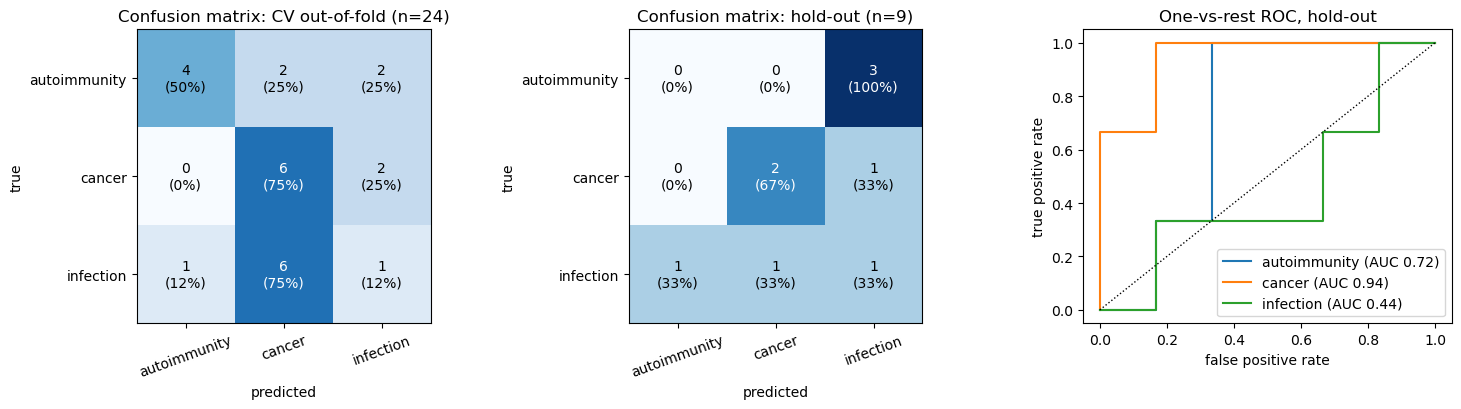

per-disease accuracy on the hold-out samples (n per disease is 1-3):


,n,accuracy
Breast_cancer,1.0,0.0
HIV,1.0,0.0
Influenza,1.0,0.0
Melanoma,1.0,1.0
NSCLC,1.0,1.0
Rheumatoid_arthritis,1.0,0.0
T1D,1.0,0.0
Tuberculosis,1.0,1.0
Ulcerative_colitis,1.0,0.0


hold-out predictions:


,sample_id,disease,disease_group,autoimmunity,cancer,infection
0,sample_9,Melanoma,cancer,0.133,0.758,0.110
1,sample_32,T1D,autoimmunity,0.299,0.131,0.570
2,sample_47,Influenza,infection,0.582,0.255,0.163
3,sample_129,Rheumatoid_arthritis,autoimmunity,0.262,0.258,0.480
4,sample_185,Ulcerative_colitis,autoimmunity,0.376,0.194,0.430
5,sample_202,Breast_cancer,cancer,0.153,0.421,0.425
6,sample_332,HIV,infection,0.201,0.424,0.374
7,sample_359,NSCLC,cancer,0.195,0.476,0.329
8,sample_521,Tuberculosis,infection,0.332,0.145,0.523


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (m, title) in zip(axes[:2], [(cv_cli, "CV out-of-fold"), (hold_metrics, "hold-out")]):
    cm = np.array(m["confusion_matrix_counts"])
    norm = np.array(m["confusion_matrix_row_normalized"])
    ax.imshow(norm, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({norm[i, j]:.0%})", ha="center", va="center",
                    color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(emb.CLASS_NAMES, rotation=20)
    ax.set_yticks(range(3)); ax.set_yticklabels(emb.CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix: {title} (n={cm.sum()})")

from sklearn.metrics import roc_curve, roc_auc_score
for c, name in enumerate(emb.CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_hold == c, P["holdout"][:, c])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_hold == c, P['holdout'][:, c]):.2f})")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].legend(loc="lower right")
axes[2].set_xlabel("false positive rate"); axes[2].set_ylabel("true positive rate"); axes[2].set_title("One-vs-rest ROC, hold-out")
plt.tight_layout()
fig.savefig(RES / "confusion_matrices_and_roc.png", dpi=130)
plt.show()

print("per-disease accuracy on the hold-out samples (n per disease is 1-3):")
display(pd.DataFrame(hold_metrics["per_disease_accuracy"]).T)
print("hold-out predictions:")
display(pd.concat([hold_meta[["sample_id", "disease", "disease_group"]].reset_index(drop=True),
                   pd.DataFrame(P["holdout"], columns=emb.CLASS_NAMES).round(3)], axis=1))

In [14]:
# A plain-language reading of the numbers above, generated from them (so it stays true if the data change).
# How good can a score look by luck? Macro AUC of RANDOM scores for the same labels (5,000 draws):
rng = np.random.default_rng(SEED)
def chance_95(y):
    return float(np.percentile([mdl.macro_auc(y, rng.dirichlet([1, 1, 1], len(y))) for _ in range(5000)], 95))

auc_cv, auc_hold = cv_cli["macro_roc_auc_pooled"], hold_metrics["macro_roc_auc_pooled"]
thr_cv, thr_hold = chance_95(y_oof), chance_95(y_hold)
print(f"CV out-of-fold (n={len(y_oof)}): macro AUC {auc_cv:.2f}; random scores exceed {thr_cv:.2f} only 5% of the time")
print(f"hold-out       (n={len(y_hold)}): macro AUC {auc_hold:.2f}; random scores exceed {thr_hold:.2f} only 5% of the time")
print("mean of the largest predicted probability per sample (1/3 = no preference):",
      {k: round(float(v.max(axis=1).mean()), 2) for k, v in P.items()})
for name, auc, thr in (("CV", auc_cv, thr_cv), ("hold-out", auc_hold, thr_hold)):
    verdict = ("within the range that chance alone produces" if auc <= thr
               else "above the 95th percentile of chance (a rough check; it ignores that the CV predictions come from different fold models)")
    print(f"-> {name}: {verdict}.")
print("With so few samples neither number supports a claim about disease signal; the run shows that the pipeline works end to end. "
      "Judge performance on the full data.")

CV out-of-fold (n=24): macro AUC 0.64; random scores exceed 0.65 only 5% of the time
hold-out       (n=9): macro AUC 0.70; random scores exceed 0.74 only 5% of the time
mean of the largest predicted probability per sample (1/3 = no preference): {'test_bulk': 0.45, 'test_sc': 0.47, 'holdout': 0.52}
-> CV: within the range that chance alone produces.
-> hold-out: within the range that chance alone produces.
With so few samples neither number supports a claim about disease signal; the run shows that the pipeline works end to end. Judge performance on the full data.


**Limitations to keep in mind** (also stated by `run_pipeline.py`): stratified CV estimates performance on new patients from the *same studies/diseases* as the training data; it cannot rule out that the model partly recognises a study rather than a disease class. `pl.run_lodo(ctx, cparams, filters, params)` (the `--lodo` option of `run_pipeline.py`) adds a leave-one-disease-out evaluation to check this (the whole chain is refit once per held-out disease; run it on the server for the full data). Earlier data checks also showed that some diseases are separable by technical fingerprints alone (e.g. `Melanoma`/`Ovarian_cancer` repertoires have no singleton clones and lack eight V genes), so a high score is not automatically biology.

## Step 6. Interpretability: SHAP

SHAP values attribute each prediction to the features, per class, on the **raw-margin (log-odds) scale** of that class's trees: a positive value pushes the sample towards the class. Here the features are the cluster-occupancy proportions (`c0`, `c1`, ...) plus `unassigned`, `evenness` and `log_depth`.

* We use exact TreeSHAP through XGBoost's own `Booster.predict(..., pred_contribs=True)` (same algorithm as `shap.TreeExplainer`). We do not call `shap.TreeExplainer` on the booster because with XGBoost 3.x it fails to parse the multi-class base score in this environment; the `shap` package is used for the **plots** only.
* Contributions are additive: for every sample and class, contributions + bias equal the model's raw output (checked below).
* If the model has learned little (see the Step 5 verdict), its predictions stay close to uniform and all SHAP values are small; the plots then illustrate the mechanics rather than reveal biology.
* The analysis uses the **test-set features**: the 6 `test_bulk` repertoires plus the 9 hold-out repertoires (SHAP needs no labels). The pipeline's `cluster_importance.csv` (written by `pl.fit_predict` in Step 4) computes the same quantity on the training samples with balanced weights.

In [15]:
X_test = np.vstack([r["X_evals"]["test_bulk"], r["X_evals"]["holdout"]])
print("explained samples:", X_test.shape[0], "(test_bulk + hold-out) x", X_test.shape[1], "features")
print("additivity check (max |contributions + bias - raw output|):", f"{ev.check_additivity(booster, X_test, names):.2e}")
phi, bias = ev.shap_contributions(booster, X_test, names)        # (samples, classes, features)

# importance table: mean |SHAP| per class, overall = sum over classes
imp = pd.DataFrame({"feature": names,
                    "type": ["cluster" if n in set(model["cluster_names"]) else "extra" for n in names]})
for c, cname in enumerate(emb.CLASS_NAMES):
    imp[cname] = np.abs(phi[:, c, :]).mean(axis=0)
imp["overall"] = imp[emb.CLASS_NAMES].sum(axis=1)
imp = imp.sort_values("overall", ascending=False).reset_index(drop=True)
imp.to_csv(RES / "shap_importance_test.csv", index=False)
display(imp.head(12).round(4))

explained samples: 15 (test_bulk + hold-out) x 23 features
additivity check (max |contributions + bias - raw output|): 6.56e-07


,feature,type,autoimmunity,cancer,infection,overall
0,c12,cluster,0.0507,0.4220,0.0353,0.5080
1,c11,cluster,0.0371,0.3191,0.0723,0.4285
2,c6,cluster,0.2028,0.2063,0.0125,0.4216
3,c16,cluster,0.2571,0.0015,0.1524,0.4110
4,c2,cluster,0.1438,0.0167,0.2032,0.3637
5,c10,cluster,0.1584,0.0057,0.1775,0.3416
6,c4,cluster,0.1500,0.0153,0.0497,0.2151
7,c7,cluster,0.0656,0.0961,0.0287,0.1905
8,c13,cluster,0.0071,0.0223,0.1256,0.1550
9,c19,cluster,0.0723,0.0344,0.0299,0.1367


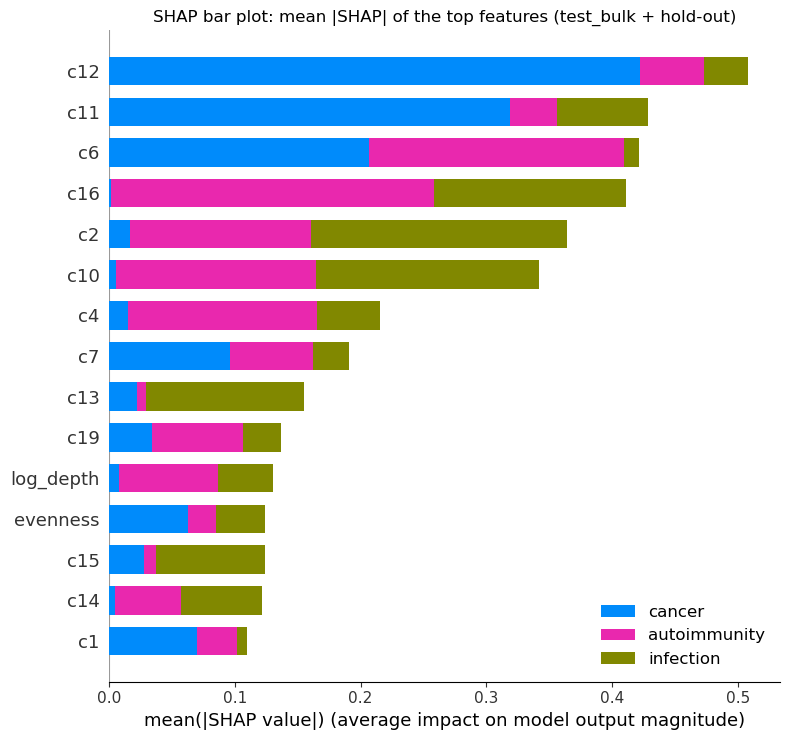

In [16]:
# SHAP bar plot: top contributing features, stacked by class (mean |SHAP|)
import shap
plt.figure()
shap.summary_plot([phi[:, c, :] for c in range(3)], X_test, feature_names=names, plot_type="bar",
                  class_names=emb.CLASS_NAMES, max_display=15, show=False)
plt.title("SHAP bar plot: mean |SHAP| of the top features (test_bulk + hold-out)")
plt.tight_layout()
plt.savefig(RES / "shap_bar.png", dpi=130, bbox_inches="tight")
plt.show()

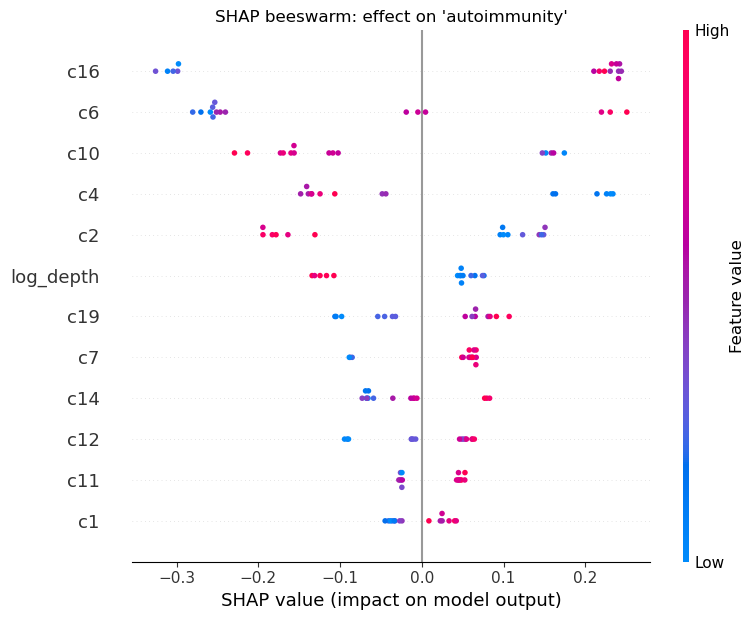

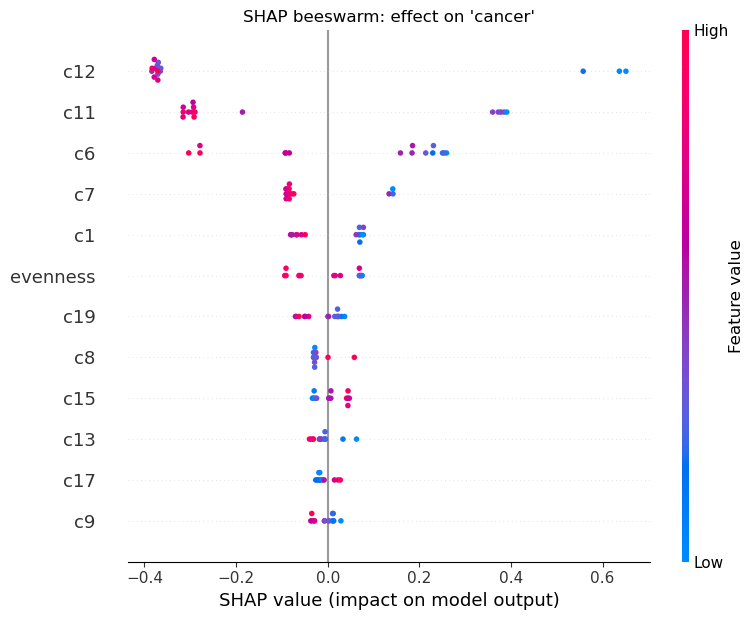

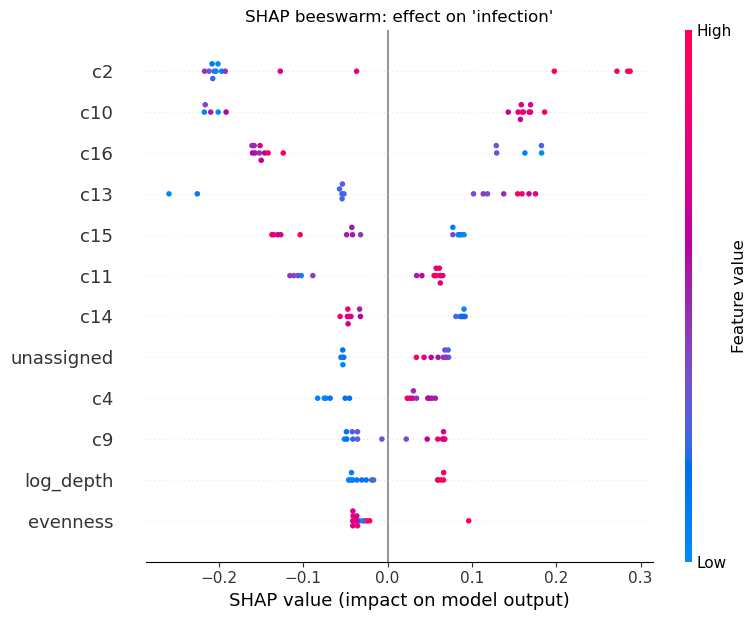

In [17]:
# SHAP summary (beeswarm) plot, one per class: each dot is a sample; x = effect on that class's log-odds,
# colour = the feature's value (red = high occupancy of the cluster)
for c, cname in enumerate(emb.CLASS_NAMES):
    plt.figure()
    shap.summary_plot(phi[:, c, :], X_test, feature_names=names, max_display=12, show=False)
    plt.title(f"SHAP beeswarm: effect on '{cname}'")
    plt.tight_layout()
    plt.savefig(RES / f"shap_beeswarm_{cname}.png", dpi=130, bbox_inches="tight")
    plt.show()

### Interpreting the features

A cluster feature is a set of sequences closest to the same k-means centroid in the SCEPTR embedding (and inside that cluster's radius); SCEPTR sees the V gene, so V usage can shape a cluster, but the clustering has no separate V-J term. A sample's value is the share of its distinct clonotypes that fall in that cluster. How to read the plots:

* **Beeswarm:** a dot far to the right is a sample for which that feature made the class more likely. If red (high occupancy) dots sit on the right, *more* sequences in that cluster push the sample towards the class; blue on the right means *fewer* of them do. A feature that matters for one class and is silent for the others marks a class-specific sequence group.
* **`unassigned`, `evenness`, `log_depth`:** repertoire-level covariates. If they rank high, the model is partly reading repertoire size or diversity rather than sequence content. `log_depth` in particular differs about 30x between bulk and single-cell data, which is why `--sc_without_log_depth` exists.
* **Caveat:** SHAP describes what *this model* uses, not causal biology. A cluster present in only one disease or one study ranks high if it identifies that study; V-gene usage is affected by technical batches (Task 1's EDA).

The cell below looks inside the highest-ranked clusters (members come from the training sequences used to build the clustering). It reports which V/J genes and CDR3 lengths they contain, a few example sequences, in how many training samples the cluster is occupied, and which single training disease contributes the largest share of the cluster's occupancy compared with what its sample count alone would give ("expected"). A cluster dominated by one disease is a likely study marker rather than a disease signature. Note that most sequences of a sample are assigned to some cluster (those beyond their cluster's radius stay *unassigned*), so most clusters are occupied in (nearly) every sample and the prevalence filter removes few clusters at this scale.

In [18]:
def cluster_members(model, label):
    keys = model["keys_sorted"][model["labels_sorted"] == label]
    parts = pd.Series([k.decode() for k in keys]).str.split("+", n=1, expand=True)
    vj = parts[1].str.split("_", n=1, expand=True)
    return pd.DataFrame({"cdr3": parts[0], "v": vj[0], "j": vj[1]})

f_tr = r["f_train"]
dis_tr = pd.Series(dis_train, index=f_tr.index)
n_per_disease = dis_tr.value_counts()
rows = []
for _, row in imp[imp["type"] == "cluster"].head(8).iterrows():
    label = int(row["feature"][1:])
    m = cluster_members(model, label)
    top_class = emb.CLASS_NAMES[int(np.argmax([row[c] for c in emb.CLASS_NAMES]))]
    mass = f_tr[row["feature"]].groupby(dis_tr).sum()          # occupancy contributed by each training disease
    top_dis = mass.idxmax()
    rows.append({"cluster": row["feature"], "SHAP overall": round(row["overall"], 3), "top class": top_class,
                 "members": len(m), "median CDR3 length": int(m["cdr3"].str.len().median()),
                 "top V (share)": f"{m['v'].value_counts().index[0]} ({m['v'].value_counts(normalize=True).iloc[0]:.0%})",
                 "top J (share)": f"{m['j'].value_counts().index[0]} ({m['j'].value_counts(normalize=True).iloc[0]:.0%})",
                 "largest disease share of occupancy": f"{top_dis} {mass.max() / mass.sum():.0%} (expected {n_per_disease[top_dis] / len(dis_tr):.0%})",
                 "samples occupied": f"{int((f_tr[row['feature']] > 0).sum())}/{len(f_tr)}",
                 "example CDR3s": ", ".join(m["cdr3"].head(3))})
cluster_table = pd.DataFrame(rows)
cluster_table.to_csv(RES / "top_cluster_summary.csv", index=False)
display(cluster_table)
ratios = {row["cluster"]: float(row["largest disease share of occupancy"].split("%")[0].split()[-1]) /
          float(row["largest disease share of occupancy"].split("expected ")[1].rstrip("%)")) for _, row in cluster_table.iterrows()}
flagged = [c for c, v in ratios.items() if v >= 2]
print("clusters whose occupancy is >= 2x concentrated in one training disease (possible study marker):", flagged or "none")
print("share of the explanatory power carried by the covariates (unassigned/evenness/log_depth):",
      f"{imp.loc[imp['type'] == 'extra', 'overall'].sum() / imp['overall'].sum():.0%}")

,cluster,SHAP overall,top class,members,median CDR3 length,top V (share),top J (share),largest disease share of occupancy,samples occupied,example CDR3s
0,c12,0.508,cancer,467,14,TRBV10-3 (52%),TRBJ2-1 (17%),Influenza 11% (expected 8%),24/24,"CAAAIEADTQYF, CAAANETFHRELFF, CAALQGAGRELGYTF"
1,c11,0.429,cancer,628,14,TRBV6-5 (68%),TRBJ1-2 (18%),CMV 10% (expected 8%),23/24,"CAANRPGEETQYF, CAAQTSGGNNEQFF, CAAWGFEGYTF"
2,c6,0.422,cancer,355,15,TRBV9 (18%),TRBJ1-2 (97%),Multiple_sclerosis 12% (expected 8%),24/24,"CAGLQVFYGYTF, CASAAYRGGAEGYGYTF, CASAQTANYGYTF"
3,c16,0.411,autoimmunity,842,15,TRBV19 (100%),TRBJ1-2 (18%),Influenza 10% (expected 8%),24/24,"CACNDRALGDNYGYTF, CAGSPTGEINSPLHF, CAIGDPPRTEAFF"
4,c2,0.364,infection,484,14,TRBV30 (100%),TRBJ2-7 (17%),CMV 14% (expected 8%),24/24,"CAAKGELRYEQYF, CACARDYGYTF, CACARVSTDTQYF"
5,c10,0.342,infection,713,15,TRBV5-6 (36%),TRBJ2-7 (20%),Influenza 10% (expected 8%),24/24,"CACRDSRFEETQYF, CACSLAWVTRDEQIF, CAGEGIRETQYF"
6,c4,0.215,autoimmunity,648,15,TRBV5-1 (96%),TRBJ2-7 (19%),CMV 10% (expected 8%),24/24,"CACHKGLDPTGELFF, CACRFWAGSDEQYF, CADWGSAKWTEAFF"
7,c7,0.190,cancer,474,15,TRBV7-9 (100%),TRBJ1-2 (18%),ESCC 9% (expected 4%),24/24,"CAHDRIANYEQYF, CAITPNGQSLNYGYTF, CARLLDSWGYNSPLHF"


clusters whose occupancy is >= 2x concentrated in one training disease (possible study marker): ['c7']
share of the explanatory power carried by the covariates (unassigned/evenness/log_depth): 8%


**What to conclude from this run.** The notebook does not state biological findings in advance, because with 24 training repertoires and 3,000 sequences each the clusters are small, noisy and dominated by whatever differs between the few studies in the subset; the verdict printed in Step 5 says how much signal the model actually found. Use the cluster table to check what makes a result believable: (i) does one disease contribute much more of a cluster's occupancy than its share of samples ("largest disease share")? (ii) do V genes or CDR3 lengths look like a single study's signature (one V gene in 100 % of a small cluster is a red flag)? (iii) how much do the covariates contribute? On the full data the same analysis is produced by `pl.fit_predict` (`cluster_importance.csv`, SHAP plots), and the top clusters' sequences can then be examined for known motifs and public clonotypes.

## Where to go next: full data and GPU

1. **Embed** each dataset with SCEPTR into `data/embeddings/sceptr/{train,test_bulk,test_sc}` on the GPU (`device="cuda"`), as in Step 2. Delete smoke-test outputs first.
2. **Tune** with the default grids (K = 300, 1000, 3000; q = 0.8, 0.9, 1.0), a Fisher filter and a strictness grid (for example percentile 1, 5, 20), `n_splits = 5` and the default Optuna trials, with `XGB_DEVICE = "cuda"`. FAISS on the GPU (`KMEANS_DEVICE = "cuda"`) needs a FAISS build that has kernels for your GPU: the PyPI `faiss-gpu-cu12` wheel works on a V100, the conda-forge build does not. Training diseases can be left out with `exclude_diseases` in `pl.load_context`.
3. **Run** the leave-one-disease-out check for the winner (`pl.run_lodo`), then `pl.fit_predict` to write `predictions_test_bulk.tsv` / `predictions_test_sc.tsv` in the required format (`sc_without_log_depth=True` adds a `test_sc` booster without `log_depth`).

Everything in this notebook is also available as command-line scripts (`scripts/run_embeddings.sh`, `scripts/run_tuning.sh`, `run_pipeline.py`) that call these same functions. No result of this tutorial says anything about full-data performance.